In [1]:
from pathlib import Path
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

In [2]:
TEKST_BREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

FONT_TEKST = "Libertinus Serif"
FONT_CIJFERS = "Libertinus Math"

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [FONT_TEKST],
    "font.size": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "figure.facecolor": "white",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.01,
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT_TEKST,
    "mathtext.it": f"{FONT_TEKST}:italic",
    "mathtext.bf": f"{FONT_TEKST}:bold",
    "axes.unicode_minus": False,
})

KLEUR_GAS = "#C98A3C"
KLEUR_ELEKTRISCH = KLEUR_HOOFD
KLEUR_AS = "#5A5E62"

UITVOER = Path("../../fig/H6")
UITVOER.mkdir(parents=True, exist_ok=True)


def duizendtal(x, _=None):
    """12.000 in plaats van 12,000."""
    return f"{x:,.0f}".replace(",", ".")


def opmaak_assen(ax, y_duizendtallen=True):
    """Huisstijl voor een grafiekvlak: schone assen, zacht raster, tabelcijfers."""
    if y_duizendtallen:
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(duizendtal))

    for kant in ("top", "right"):
        ax.spines[kant].set_visible(False)
    for kant in ("left", "bottom"):
        ax.spines[kant].set_color(KLEUR_AS)

    ax.tick_params(colors="black")
    ax.grid(axis="y")
    ax.set_axisbelow(True)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontfamily(FONT_CIJFERS)

    return ax

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
verlichting = Path("../../data/H6/verlichtingspunten-per-jaar.xlsx")
df_verlichting = pd.read_excel(verlichting)
print(df_verlichting.shape, list(df_verlichting.columns))
df_verlichting.head()

(101, 5) ['jaar', 'gas', 'olie', 'elektrisch', 'opm']


,jaar,gas,olie,elektrisch,opm
0,1840,0.0,NaN,NaN,NaN
1,1841,NaN,NaN,NaN,NaN
2,1842,NaN,NaN,NaN,NaN
3,1843,NaN,NaN,NaN,NaN
4,1844,NaN,NaN,NaN,NaN


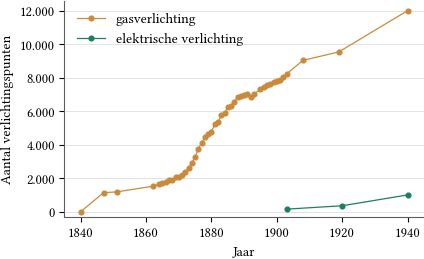

In [4]:
REEKSEN = [("gas", KLEUR_GAS, "gasverlichting", 0.9),
           ("elektrisch", KLEUR_ELEKTRISCH, "elektrische verlichting", 0.9)]

fig, ax = plt.subplots(figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.66))

for kol, kleur, label, dikte in REEKSEN:

    reeks = df_verlichting.dropna(subset=[kol]).sort_values("jaar")

    ax.plot(reeks["jaar"], reeks[kol], marker="o", markersize=3.4,
            linewidth=dikte, color=kleur, label=label)

ax.set_xlim(1835, 1945)
ax.set_xticks(range(1840, 1945, 20))
ax.set_ylim(-300, 12600)
ax.set_yticks(range(0, 12001, 2000))
ax.set_xlabel("Jaar")
ax.set_ylabel("Aantal verlichtingspunten")

opmaak_assen(ax)

ax.legend(frameon=False, loc="upper left")

pas_breedte_aan(fig)
fig.savefig(UITVOER / "6.3_verlichtingspunten_1840_1940.png", dpi=300)

plt.show()

In [5]:
MACRO = Path("../../data/algemeen/gebeurtenisdata_macro")

bestanden = sorted(p for p in MACRO.glob("*.xlsx")
                   if not p.name.startswith(("~$", "._")))
print(len(bestanden))

197


In [6]:
delen = []
for p in bestanden:
    d = pd.read_excel(p)
    d["bestand"] = p.stem
    delen.append(d)

df_macro = pd.concat(delen, ignore_index=True)
print(df_macro.shape)

(383125, 43)


In [7]:
df_macro["E_DATE_clean"] = pd.to_datetime(df_macro["E_DATE_clean"],
                                          errors="coerce")
jaar = df_macro["E_DATE_clean"].dt.year

zonder_datum = jaar.isna().sum()
df_macro = df_macro[jaar.between(1876, 1939)].copy()
print(len(df_macro))
df_macro.columns

/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_31794/4281932864.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_macro["E_DATE_clean"] = pd.to_datetime(df_macro["E_DATE_clean"],


372115


Index(['bron', 'archive_file', 'year', 'district', 'Person ID',
       'Incident Number', 'Page Number', 'E_DATE', 'E_TIME', 'E_LOC',
       'P_LASTNAME', 'P_FIRSTNAME', 'P_PROF', 'P_BIRTHPLACE', 'P_BIRTHDATE',
       'P_RES', 'P_TITLE', 'P_MARITALSTATUS', 'P_AGE', 'E_DATE_clean',
       'E_TIME_clean', 'E_TIME_grouped', 'E_LOC_gis1898',
       'firstname_firstword', 'gender_inferred', 'firstname_match',
       'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass', 'E_YEAR',
       'P_AGE_clean', 'P_BIRTHYEAR', 'P_AGE_categories', 'P_BIRTHPLACE_extra',
       'P_BIRTHPLACE_cleaned', 'P_BIRTHPLACE_match', 'P_BIRTHPLACE_country',
       'P_BIRTHPLACE_dis', 'P_BIRTHPLACE_sim', 'astro', 'incident_text',
       'E_LOC_gis1898_oud', 'bestand'],
      dtype='object')

In [8]:
PERIODE = (1876, 1939)
WOI = (1914, 1918)
DREMPEL = 1000           
GRENS = 1903 # eerste elektrische straatverlichting

NACHT = {"nacht", "avondschemering", "ochtendschemering"}
DAG = {"dag"}

In [9]:
d = df_macro.copy()
d["jaar"] = pd.to_datetime(d["E_DATE_clean"], errors="coerce").dt.year
d["cat"] = d["astro"].str.strip().str.lower()

per_jaar = (d.assign(bekend=d["cat"].isin(NACHT | DAG),
                     nacht=d["cat"].isin(NACHT))
            .groupby("jaar")
            .agg(totaal=("bekend", "size"),
                 n=("bekend", "sum"),
                 nacht=("nacht", "sum"))
            .reset_index())

per_jaar["aandeel"] = per_jaar["nacht"] / per_jaar["n"]
per_jaar["dekking"] = per_jaar["n"] / per_jaar["totaal"]

In [10]:
lampen_ruw = pd.read_excel(verlichting)
lampen_ruw.loc[lampen_ruw["jaar"] < GRENS, "elektrisch"] = (
    lampen_ruw.loc[lampen_ruw["jaar"] < GRENS, "elektrisch"].fillna(0))

lampen = (lampen_ruw.set_index("jaar")[["gas", "elektrisch"]]
          .reindex(range(PERIODE[0], 1941))
          .interpolate(method="index", limit_area="inside"))
lampen["totaal"] = lampen["gas"] + lampen["elektrisch"]

In [11]:
samen = (per_jaar.merge(lampen["totaal"].rename_axis("jaar")
                        .reset_index(name="lantaarns"),
                        on="jaar")
         .dropna(subset=["lantaarns"])
         .query("n >= @DREMPEL and not (@WOI[0] <= jaar <= @WOI[1])")
         .sort_values("jaar"))

print(f"{len(samen)} jaren, {samen['jaar'].min()}–{samen['jaar'].max()}, "
      f"{samen['n'].sum():,} bruikbare registraties".replace(",", "."))
print(f"dekking: {samen['dekking'].min():.2f} tot {samen['dekking'].max():.2f} "
      f"(mediaan {samen['dekking'].median():.2f})\n")


49 jaren. 1876–1939. 185.120 bruikbare registraties
dekking: 0.20 tot 0.74 (mediaan 0.53)



In [12]:
rho, p = stats.spearmanr(samen["totaal"], samen["aandeel"])
print(f"niveaus:         rho = {rho:+.3f}, p = {p:.3f}, n = {len(samen)}")

verschil = samen[["totaal", "aandeel"]].diff().dropna()
rho_d, p_d = stats.spearmanr(verschil["totaal"], verschil["aandeel"])
print(f"jaarverschillen: rho = {rho_d:+.3f}, p = {p_d:.3f}, n = {len(verschil)}")

gewicht = samen["n"] / samen["n"].mean()
x = samen["totaal"] / 1000
helling, snijpunt = np.polyfit(x, samen["aandeel"], 1, w=np.sqrt(gewicht))

rest = samen["aandeel"] - (snijpunt + helling * x)
se = np.sqrt((gewicht * rest**2).sum() / (gewicht.sum() - 2)
             / (gewicht * (x - np.average(x, weights=gewicht))**2).sum())
marge = stats.t.ppf(0.975, len(samen) - 2) * se

print(f"helling: {helling*100:+.2f} procentpunt per 1.000 lantaarns "
      f"(95%-BI {(helling-marge)*100:+.2f} tot {(helling+marge)*100:+.2f})\n")

niveaus:         rho = -0.675, p = 0.000, n = 49
jaarverschillen: rho = +0.041, p = 0.780, n = 48
helling: -0.69 procentpunt per 1.000 lantaarns (95%-BI -0.99 tot -0.38)



In [13]:
# ── Verband met vertraging: lantaarns van x jaar geleden ───────────────
for lag in range(0, 11, 2):
    d = samen.copy()
    d["lantaarns_lag"] = d["lantaarns"].shift(lag)
    d = d.dropna(subset=["lantaarns_lag"])
    rho, p = stats.spearmanr(d["lantaarns_lag"].diff().dropna(),
                             d["aandeel"].diff().dropna())
    print(f"vertraging {lag:>2} jaar: rho = {rho:+.3f}, p = {p:.3f}, n = {len(d)-1}")

vertraging  0 jaar: rho = -0.235, p = 0.108, n = 48
vertraging  2 jaar: rho = -0.010, p = 0.949, n = 46
vertraging  4 jaar: rho = +0.004, p = 0.978, n = 44
vertraging  6 jaar: rho = -0.096, p = 0.547, n = 42
vertraging  8 jaar: rho = +0.143, p = 0.379, n = 40
vertraging 10 jaar: rho = -0.048, p = 0.773, n = 38


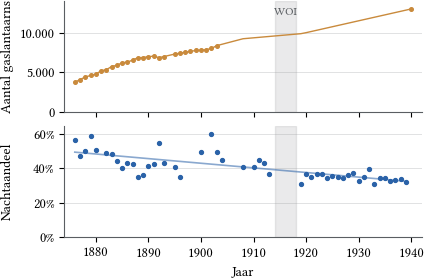

In [14]:
fig, (boven, onder) = plt.subplots(2, 1, sharex=True,
                                   figsize=(TEKST_BREEDTE, TEKST_BREEDTE * 0.72),
                                   gridspec_kw={"hspace": 0.12})

# ── Boven: aantal lantaarns ────────────────────────────────────────────
reeks = lampen.loc[1876:1940, "totaal"].dropna()
boven.plot(reeks.index, reeks.values, color=KLEUR_GAS, linewidth=1.0, zorder=2)

volledig = lampen_ruw[lampen_ruw["jaar"].between(1876, 1940)
                      & lampen_ruw["gas"].notna()
                      & lampen_ruw["elektrisch"].notna()]
boven.plot(volledig["jaar"], volledig["gas"] + volledig["elektrisch"],
           marker="o", markersize=2.6, linewidth=0, color=KLEUR_GAS, zorder=3)

boven.set_ylabel("Aantal gaslantaarns")
boven.set_ylim(0, 14000)
boven.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(duizendtal))

# ── Onder: nachtaandeel, losse punten ──────────────────────────────────
nacht = samen.sort_values("jaar")
onder.plot(nacht["jaar"], nacht["aandeel"] * 100, marker="o", markersize=2.8,
           linewidth=0, color=KLEUR_NACHT, zorder=3)

onder.set_ylabel("Nachtaandeel")
onder.set_xlabel("Jaar")
onder.set_ylim(0, 65)
onder.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))

# ── Gedeelde opmaak ────────────────────────────────────────────────────
# ── Onder: nachtaandeel, losse punten met lineaire trend ───────────────


helling, snijpunt = np.polyfit(nacht["jaar"], nacht["aandeel"] * 100, 1)
jaren = np.array([nacht["jaar"].min(), nacht["jaar"].max()])
onder.plot(jaren, snijpunt + helling * jaren, color=KLEUR_NACHT,
           linewidth=1.2, alpha=0.55, zorder=2)

for ax in (boven, onder):
    ax.axvspan(1914, 1918, color="#96999B", alpha=0.20, zorder=0)
    ax.set_xlim(1874, 1942)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(colors="black")
    for kant in ("top", "right"):
        ax.spines[kant].set_visible(False)
    for kant in ("left", "bottom"):
        ax.spines[kant].set_color(KLEUR_AS)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontfamily(FONT_CIJFERS)

onder.set_xticks(range(1880, 1941, 10))
boven.text(1916, 13200, "WOI", ha="center", va="top",
           fontsize=CORPS_KLEIN, color="#5A5E62")

fig.align_ylabels([boven, onder])

pas_breedte_aan(fig)
fig.savefig(UITVOER / "6.10_lantaarns_en_nachtaandeel.png", dpi=300)
plt.show()

In [15]:
per_decennium = (samen.assign(decennium=(samen["jaar"] // 10) * 10)
                 .groupby("decennium")
                 .agg(jaren=("jaar", "size"),
                      nacht=("nacht", "sum"),
                      totaal=("n", "sum")))
per_decennium["dag"] = per_decennium["totaal"] - per_decennium["nacht"]

# per jaar, want de decennia bevatten niet evenveel jaren
for kol in ("nacht", "dag", "totaal"):
    per_decennium[f"{kol}/jaar"] = (per_decennium[kol]
                                    / per_decennium["jaren"]).round(0)

print(per_decennium[["jaren", "nacht/jaar", "dag/jaar", "totaal/jaar"]]
      .to_string())

           jaren  nacht/jaar  dag/jaar  totaal/jaar
decennium                                          
1870           4      1173.0    1093.0       2266.0
1880           9      1098.0    1498.0       2596.0
1890           6       939.0    1252.0       2191.0
1900           5       675.0     709.0       1384.0
1910           5      1596.0    2468.0       4064.0
1920          10      1717.0    3099.0       4816.0
1930          10      2160.0    4254.0       6414.0


In [16]:
MESO = Path("../../data/algemeen/gebeurtenisdata_meso/steekproefdatabank.xlsx")

df_meso = pd.read_excel(MESO)
print(df_meso.shape)
print(list(df_meso.columns))

(5840, 30)
['ID', 'archive_file', 'incidentnumber', 'year', 'district', 'date', 'hour', 'loc_street', 'rol', 'positie', 'lastname', 'firstname', 'gender', 'burgerlijke staat', 'age', 'birthcountry', 'birthplace', 'profession', 'prof_hisco', 'residence_country', 'residence_place', 'residence_street', 'residence_housenumber', 'category', 'subcategory', 'description(short)', 'description(long)', 'notes', 'hour_processed', 'E_TIME_astro']


In [17]:
print(df_meso["E_TIME_astro"].value_counts(dropna=False))
print()
print(df_meso["category"].value_counts(dropna=False).head(20))
print()
print(df_meso["year"].describe())

E_TIME_astro
dag               3501
nacht             2131
avondschemer       129
ochtendschemer      64
unknown             15
Name: count, dtype: int64

category
OpenbareOrde         1819
Verkeer              1249
Overig                582
Vermogensdelict       533
Geweldsdelict         502
Dienstmededeling      329
Hygiëne               210
Colportage            194
Economie              191
Verloren-gevonden      77
Gezondheid             62
verkeer                36
Zedendelict            24
Bouw                   21
NaN                    11
Name: count, dtype: int64

count    5840.000000
mean     1901.570890
std        14.233072
min      1889.000000
25%      1889.000000
50%      1900.000000
75%      1905.000000
max      1931.000000
Name: year, dtype: float64


In [18]:
NACHT = {"nacht", "avondschemer", "ochtendschemer"}
DAG = {"dag"}
GRENS = 1905                    # mediaan van de reeks; vroeg tegenover laat

d = df_meso.copy()
d["cat_astro"] = d["E_TIME_astro"].astype(str).str.strip().str.lower()
d["category"] = d["category"].astype(str).str.strip().str.capitalize()
d = d[d["cat_astro"].isin(NACHT | DAG)]
d["nacht"] = d["cat_astro"].isin(NACHT)
d["laat"] = d["year"] >= GRENS

print(d.groupby("laat")["year"].agg(["min", "max", "size"]).to_string())
print()

overzicht = (d.groupby(["category", "laat"]).size().unstack(fill_value=0)
             .rename(columns={False: "vroeg", True: "laat"}))
overzicht["vroeg %"] = (overzicht["vroeg"] / overzicht["vroeg"].sum() * 100).round(1)
overzicht["laat %"] = (overzicht["laat"] / overzicht["laat"].sum() * 100).round(1)
overzicht["verschil"] = (overzicht["laat %"] - overzicht["vroeg %"]).round(1)
overzicht["% nacht"] = d.groupby("category")["nacht"].mean().mul(100).round(1)

print(overzicht.sort_values("verschil", ascending=False).to_string())

        min   max  size
laat                   
False  1889  1904  4361
True   1905  1931  1464

laat               vroeg  laat  vroeg %  laat %  verschil  % nacht
category                                                          
Verkeer              707   571     16.2    39.0      22.8     19.2
Gezondheid             1    61      0.0     4.2       4.2     22.6
Overig               420   157      9.6    10.7       1.1     39.2
Nan                    0    11      0.0     0.8       0.8     36.4
Hygiëne              151    58      3.5     4.0       0.5     39.2
Zedendelict           14    10      0.3     0.7       0.4     50.0
Bouw                  15     6      0.3     0.4       0.1     28.6
Vermogensdelict      407   125      9.3     8.5      -0.8     35.2
Verloren-gevonden     69     8      1.6     0.5      -1.1     42.9
Geweldsdelict        389   112      8.9     7.7      -1.2     51.3
Dienstmededeling     269    60      6.2     4.1      -2.1     47.7
Colportage           171    23  

In [19]:
GRENS = 1905
NACHT = {"nacht", "avondschemer", "ochtendschemer"}

oo = d[(d["category"] == "Openbareorde") & d["nacht"]].copy()

print(oo.groupby("laat")["year"].agg(["min", "max", "size"]).to_string())
print()

sub = (oo.groupby(["subcategory", "laat"]).size().unstack(fill_value=0)
       .rename(columns={False: "vroeg", True: "laat"}))
sub["vroeg %"] = (sub["vroeg"] / sub["vroeg"].sum() * 100).round(1)
sub["laat %"] = (sub["laat"] / sub["laat"].sum() * 100).round(1)
sub["verschil"] = (sub["laat %"] - sub["vroeg %"]).round(1)

print(sub.sort_values("verschil", ascending=False).to_string())

        min   max  size
laat                   
False  1889  1904   875
True   1905  1931   153

laat            vroeg  laat  vroeg %  laat %  verschil
subcategory                                           
Zeden              61    20      7.0    13.1       6.1
Wanorder          172    37     19.7    24.2       4.5
Dronkenschap      317    60     36.2    39.2       3.0
Overig              0     2      0.0     1.3       1.3
Verbaal geweld      0     2      0.0     1.3       1.3
zeden               0     2      0.0     1.3       1.3
Landloperij        28     6      3.2     3.9       0.7
wanorder            1     0      0.1     0.0      -0.1
Optocht             4     0      0.5     0.0      -0.5
nachtlawaai         9     0      1.0     0.0      -1.0
Honden             13     0      1.5     0.0      -1.5
Bedelarij          50     6      5.7     3.9      -1.8
Nachtlawaai       110    13     12.6     8.5      -4.1
Entertainment     110     5     12.6     3.3      -9.3


In [20]:
import re
import pandas as pd

paardwoorden = {
    "paard",
    "paarden",
    "peerd",
    "paarde",
    "paert",
    "peerde",
    "paerd",
    "peerdeken"
}

def vind_paardwoorden(text):
    if pd.isna(text):
        return []

    woorden = re.findall(r"\b[\w'-]+\b", str(text).lower())
    return [woord for woord in woorden if woord in paardwoorden]

df = df_macro.copy()

WIJKGROEPEN = {
    6: "wijk 6 (De Keyserlei)",
    3: "wijk 3",
    5: "wijken 5 en 11 (Gasstraat)",
    11: "wijken 5 en 11 (Gasstraat)",
}
df["wijkgroep"] = pd.to_numeric(df["district"], errors="coerce").map(WIJKGROEPEN)

df["paard_matches"] = df["incident_text"].apply(vind_paardwoorden)
df["paard_match"] = df["paard_matches"].str.len() > 0

In [21]:
from collections import Counter

tellingen = Counter(
    woord
    for matches in df["paard_matches"]
    for woord in matches
)

print(pd.Series(tellingen).sort_values(ascending=False))

paard        13493
paarden       3437
peerd          364
paarde         288
paert           71
peerde          37
paerd           32
peerdeken       10
dtype: int64


In [22]:
interbellum = df[
    (df["year"] >= 1919) &
    (df["year"] <= 1939) &
    df["wijkgroep"].notna()
].copy()

samenvatting = (
    interbellum
    .groupby("wijkgroep")
    .agg(
        incidenten=("incident_text", "size"),
        paardincidenten=("paard_match", "sum")
    )
)

samenvatting["per_1000"] = (
    samenvatting["paardincidenten"] /
    samenvatting["incidenten"] * 1000
)

print(samenvatting.round(1))

                            incidenten  paardincidenten  per_1000
wijkgroep                                                        
wijk 3                           79081             3595      45.5
wijk 6 (De Keyserlei)            52220              670      12.8
wijken 5 en 11 (Gasstraat)       35955             1507      41.9


In [23]:
df_macro.columns

Index(['bron', 'archive_file', 'year', 'district', 'Person ID',
       'Incident Number', 'Page Number', 'E_DATE', 'E_TIME', 'E_LOC',
       'P_LASTNAME', 'P_FIRSTNAME', 'P_PROF', 'P_BIRTHPLACE', 'P_BIRTHDATE',
       'P_RES', 'P_TITLE', 'P_MARITALSTATUS', 'P_AGE', 'E_DATE_clean',
       'E_TIME_clean', 'E_TIME_grouped', 'E_LOC_gis1898',
       'firstname_firstword', 'gender_inferred', 'firstname_match',
       'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass', 'E_YEAR',
       'P_AGE_clean', 'P_BIRTHYEAR', 'P_AGE_categories', 'P_BIRTHPLACE_extra',
       'P_BIRTHPLACE_cleaned', 'P_BIRTHPLACE_match', 'P_BIRTHPLACE_country',
       'P_BIRTHPLACE_dis', 'P_BIRTHPLACE_sim', 'astro', 'incident_text',
       'E_LOC_gis1898_oud', 'bestand'],
      dtype='object')

In [24]:
# Eerst alleen relevante wijken
d = df[df["wijkgroep"].notna()].copy()

# Unieke gebeurtenis-id maken
d["event_id"] = (
    d["archive_file"].astype(str)
    + "_"
    + d["Incident Number"].astype(str)
)

# Dedupliceren op gebeurtenisniveau
# We nemen per gebeurtenis de eerste rij, maar bewaren paard_match als:
# True zodra minstens één persoonsrij binnen die gebeurtenis een paardvermelding heeft
events = (
    d.groupby(
        ["event_id", "archive_file", "Incident Number", "year", "wijkgroep"],
        as_index=False
    )
    .agg(
        paard_match=("paard_match", "max")
    )
)

# Interbellum
interbellum = events[
    (events["year"] >= 1919) &
    (events["year"] <= 1939)
].copy()

# Samenvatting per wijkgroep
samenvatting = (
    interbellum
    .groupby("wijkgroep")
    .agg(
        incidenten=("event_id", "nunique"),
        paardincidenten=("paard_match", "sum")
    )
)

samenvatting["per_1000"] = (
    samenvatting["paardincidenten"] /
    samenvatting["incidenten"] * 1000
)

print(samenvatting.round(1))

                            incidenten  paardincidenten  per_1000
wijkgroep                                                        
wijk 3                           32120             1156      36.0
wijk 6 (De Keyserlei)            20769              159       7.7
wijken 5 en 11 (Gasstraat)       15833              471      29.7


In [25]:
# Alleen De Keyserlei en Gasstraat
straten = df[
    df["E_LOC_gis1898"].isin(["DE KEYSERLEI", "GASSTRAAT"])
].copy()

# Naar gebeurtenisniveau:
# paard_match = True als minstens één rij van de gebeurtenis een paardmatch heeft
events_straten = (
    straten
    .groupby(
        [
            "archive_file",
            "Incident Number",
            "year",
            "E_LOC_gis1898"
        ],
        as_index=False
    )
    .agg(
        paard_match=("paard_match", "max")
    )
)

# Per jaar en straat
per_jaar = (
    events_straten
    .groupby(["year", "E_LOC_gis1898"])
    .agg(
        incidenten=("Incident Number", "size"),
        paardincidenten=("paard_match", "sum")
    )
    .reset_index()
)

per_jaar["per_1000"] = (
    per_jaar["paardincidenten"] /
    per_jaar["incidenten"] * 1000
)

print(
    per_jaar
    .sort_values(["E_LOC_gis1898", "year"])
    .to_string(index=False)
)

 year E_LOC_gis1898  incidenten  paardincidenten    per_1000
 1877  DE KEYSERLEI           1                0    0.000000
 1878  DE KEYSERLEI           1                0    0.000000
 1880  DE KEYSERLEI           2                0    0.000000
 1881  DE KEYSERLEI           1                1 1000.000000
 1885  DE KEYSERLEI           3                0    0.000000
 1887  DE KEYSERLEI           5                0    0.000000
 1888  DE KEYSERLEI           2                0    0.000000
 1889  DE KEYSERLEI           1                0    0.000000
 1890  DE KEYSERLEI           3                0    0.000000
 1891  DE KEYSERLEI           1                0    0.000000
 1894  DE KEYSERLEI           4                0    0.000000
 1895  DE KEYSERLEI          41                1   24.390244
 1896  DE KEYSERLEI          53                2   37.735849
 1899  DE KEYSERLEI           1                1 1000.000000
 1902  DE KEYSERLEI         131                5   38.167939
 1903  DE KEYSERLEI     

In [26]:
events_straten["periode"] = pd.NA

events_straten.loc[
    events_straten["year"].between(1876, 1899),
    "periode"
] = "1876–1899"

events_straten.loc[
    events_straten["year"].between(1919, 1939),
    "periode"
] = "1919–1939"

samenvatting_straten = (
    events_straten[
        events_straten["periode"].notna()
    ]
    .groupby(["E_LOC_gis1898", "periode"])
    .agg(
        incidenten=("Incident Number", "size"),
        paardincidenten=("paard_match", "sum")
    )
)

samenvatting_straten["per_1000"] = (
    samenvatting_straten["paardincidenten"] /
    samenvatting_straten["incidenten"] * 1000
)

print(samenvatting_straten.round(1))

                         incidenten  paardincidenten  per_1000
E_LOC_gis1898 periode                                         
DE KEYSERLEI  1876–1899         119                5      42.0
              1919–1939        1048               14      13.4
GASSTRAAT     1876–1899          28                1      35.7
              1919–1939         206               12      58.3


In [27]:
nachtwaarden = ["ochtendschemering", "avondschemering", "nacht"]

dekeyser_1930 = (
    df[
        (df["E_LOC_gis1898"] == "DE KEYSERLEI") &
        (df["year"].between(1930, 1939)) &
        (df["astro"].isin(nachtwaarden))
    ]
    .drop_duplicates(["archive_file", "Incident Number"])
    .copy()
)

print("Aantal nachtelijke gebeurtenissen:", len(dekeyser_1930))

Aantal nachtelijke gebeurtenissen: 251


In [28]:
import re
from collections import Counter

woorden = Counter()

for text in dekeyser_1930["incident_text"].dropna():
    for woord in re.findall(r"\b[\w'-]+\b", text.lower()):
        if (
            "auto" in woord
            or "motor" in woord
            or "rijtuig" in woord
        ):
            woorden[woord] += 1

print(pd.Series(woorden).sort_values(ascending=False).to_string())

auto               133
rijtuig             37
autorijtuig         30
tramrijtuig         18
autovoerder         12
autos                7
autobus              6
rijtuigen            4
autovoertuig         4
autorituig           3
autovoerde           3
autorij              3
autotaxi             3
autoplaat            3
autovolgnumer        2
automatique          2
autobewaker          2
autorytuig           2
autotaxei            2
personenauto         2
autowagen            1
autotasa             1
autovoerd            1
autotas              1
autovolg             1
autobuste            1
autocor              1
autopersonen         1
autobusser           1
autotaxirituig       1
tamrijtuig           1
motors               1
autovoer             1
autoveer             1
autozieken           1
autoziekenwagen      1
personenautos        1
taxirijtuig          1
autorijtuigen        1
luxauto              1
autorijkuig          1
autorituigen         1
autocamion           1
autodryver 

In [29]:
autotermen = {
    "auto", "autos",
    "autorijtuig", "autorijtuigen",
    "autorituig", "autorituigen",
    "autorij", "autorijkuig", "autorytuig",
    "autovoertuig",
    "personenauto", "personenautos",
    "autobus", "autobuste", "autobusser",
    "autotaxi", "autotaxei", "autotaxirituig",
    "autowagen", "autocamion",
    "luxauto",
    "autoongeval",
    "motorijtuig"
}

def bevat_auto(text):
    if pd.isna(text):
        return False
    woorden = set(re.findall(r"\b[\w'-]+\b", str(text).lower()))
    return bool(woorden & autotermen)

dekeyser_1930["auto"] = dekeyser_1930["incident_text"].apply(bevat_auto)

n_totaal = len(dekeyser_1930)
n_auto = dekeyser_1930["auto"].sum()

print("Nachtelijke gebeurtenissen:", n_totaal)
print("Met autovermelding:", n_auto)
print(f"Aandeel: {n_auto/n_totaal:.1%}")

Nachtelijke gebeurtenissen: 251
Met autovermelding: 93
Aandeel: 37.1%


In [30]:
straten = ["DE KEYSERLEI", "GASSTRAAT"]

publiek = df[
    df["E_LOC_gis1898"].isin(straten) &
    df["P_BIRTHPLACE_dis"].notna()
].copy()

publiek["periode"] = pd.cut(
    publiek["year"],
    bins=[1875, 1899, 1918, 1939],
    labels=["1876–1899", "1900–1918", "1919–1939"]
)

resultaat = (
    publiek[
        publiek["periode"].isin(["1876–1899", "1919–1939"])
    ]
    .groupby(["E_LOC_gis1898", "periode"], observed=True)
    ["P_BIRTHPLACE_dis"]
    .agg(
        n="count",
        mediaan="median",
        gemiddelde="mean"
    )
    .round(1)
)

print(resultaat)

                           n  mediaan  gemiddelde
E_LOC_gis1898 periode                            
DE KEYSERLEI  1876–1899   75     12.6        68.8
              1919–1939  981     22.4        90.2
GASSTRAAT     1876–1899   18      9.4        29.7
              1919–1939  144      7.1        39.1
